# 11E — Stopwatch-twin discordance

**Hypothesis (S11E).** Within pairs of same-position prospects whose official forty times are near-identical (the 09C rule: within 0.03 s), the direction of a reliable tracking difference agrees with the direction of the later NFL movement difference more often than chance.

**Design.** The 09C pairs are the candidate pool; a pair is used for a feature × target only when BOTH athletes have both values (`twins_transfer.pair_frame`). ΔX = X_b − X_a (09C orientation). Statistics: sign concordance (ties dropped), Spearman of Δ, conditional slope of ΔNFL on ΔCombine given Δforty and Δten (through the origin).

**Dependence.** An athlete appears in many pairs: intervals come from an athlete-cluster bootstrap (a pair's weight = product of its athletes' multiplicities), a component bootstrap, and a disjoint matching (each athlete once). Controls: random same-position pairs, wrong features, NFL values reshuffled within position, reliability-weighted pairs.

**Language.** These are associations between differences — never a statement that a tracking difference causes an NFL difference.

**Prerequisites.** 09C, 11.0, 11B.

In [1]:
RUN_MODE = 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
N_CONTROL = 200               # random-pair and reshuffle replicates per feature × target

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import numpy as np
import polars as pl
from IPython.display import Markdown, display

from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement.artifacts import DiscoveryStore
from nflbdb.research.advanced_movement.m11 import assemble as asm
from nflbdb.research.advanced_movement.m11 import config as m11c
from nflbdb.research.advanced_movement.m11 import figures as fg
from nflbdb.research.advanced_movement.m11 import reporting as rp
from nflbdb.research.advanced_movement.m11 import sources as src
from nflbdb.research.advanced_movement.m11 import speed_state as ss
from nflbdb.research.advanced_movement.m11 import tournament as tn
from nflbdb.research.advanced_movement.m11 import twins_transfer as tw
from nflbdb.research.advanced_movement.m11 import validation as v11

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = DiscoveryStore(cfg, controls)
amc.seed_everything(controls.seed)
C = m11c.M11Config().for_mode(controls)
S = src.M11Sources(cfg, store, C)
PROV = m11c.provenance('11E', controls, C)
W = store.write_frame
twins = S.twins()
envw = ss.envelope_wide(store.read_frame('m11_envelopes', src.NB['11B'])) if store.has('m11_envelopes') else None
values = asm.linked_table(store, extra=[envw] if envw is not None else [], nfl_required=False)
athf = asm.foundation(store, 'm11_athlete_features')
se = athf.with_columns((pl.col('sd_attempts') / pl.col('n_attempts').cast(pl.Float64).sqrt()).alias('se')).filter(pl.col('n_attempts') >= 2).pivot(on='feature', index='nfl_id', values='se')
positions = values.select('nfl_id', 'position_group')
label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · {twins.height:,} stopwatch-twin pairs in the 09C pool'))
checks = v11.run_all(v11.CHECKS_STATS)
display(checks)
v11.assert_all_passed(checks)

**Run mode: `full`** (FULL) · 3,266 stopwatch-twin pairs in the 09C pool

check,status,detail
str,str,str
"""resampling_and_comparison""","""PASS""","""paired athlete bootstrap: null…"
"""pair_overlap_resampling""","""PASS""","""pair resampling is by athlete …"
"""mixed_model_and_twins""","""PASS""","""EM mixed model recovers slope …"


## 1 · Eligible pairs and the overlap structure

Not every 09C pair is NFL-linked. For each declared feature × target, the eligible pairs are those where both athletes have both values. The overlap network shows how strongly pairs share athletes (why pairs cannot be bootstrapped independently).

combine,nfl,kind,n_pairs,n_athletes
str,str,str,i64,i64
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""","""matched""",1341,230
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""","""matched""",767,113
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""","""matched""",1814,303
"""forty.phase_A0""","""env.lin_A0""","""matched""",1937,317
"""forty.phase_V0""","""env.lin_V0""","""matched""",1937,317
"""forty.v_max_obs""","""nfl.vmax_p90""","""matched""",900,146
"""forty.early_accel""","""nfl.accel_low_mean""","""matched""",1800,307
"""short_shuttle.decel_mean""","""nfl.brake_decel""","""matched""",172,91
"""forty.band_2_4_mean_accel""","""nfl.band_6_8""","""control""",767,113


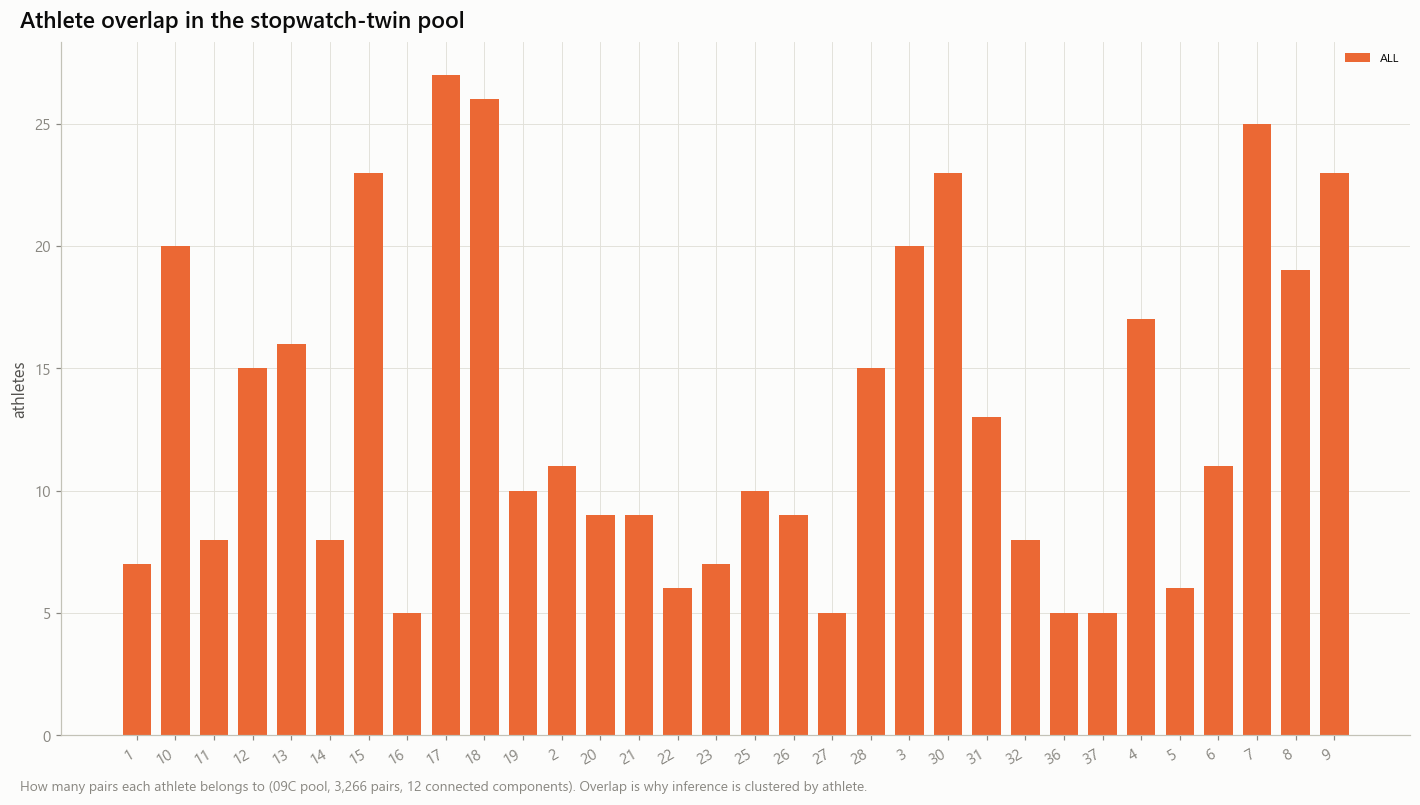

In [3]:
elig = []
PF = {}
for p in tw.TWIN_PAIRS:
    if p.combine in values.columns and p.nfl in values.columns:
        PF[(p.combine, p.nfl)] = tw.pair_frame(twins, values, p.combine, p.nfl, se)
        f = PF[(p.combine, p.nfl)]
        elig.append({'combine': p.combine, 'nfl': p.nfl, 'kind': p.kind, 'n_pairs': f.height, 'n_athletes': len(set(f['nfl_id_a'].to_list()) | set(f['nfl_id_b'].to_list())) if f.height else 0})
    else:
        elig.append({'combine': p.combine, 'nfl': p.nfl, 'kind': p.kind, 'n_pairs': 0, 'n_athletes': 0})
ELIG = pl.DataFrame(elig)
W(ELIG, 'm11_twin_eligibility')
display(ELIG)
net = tw.overlap_network(twins)
W(net['degree'], 'm11_twin_degree')
W(net['components'], 'm11_twin_components')
deg = net['degree'].group_by('n_pairs').len().sort('n_pairs').rename({'n_pairs': 'pairs per athlete', 'len': 'athletes'})
store.show(fg.fig_grouped_bars(deg.with_columns(pl.col('pairs per athlete').cast(pl.String), pl.lit('ALL').alias('g')), 'pairs per athlete', 'g', 'athletes',
                               'Athlete overlap in the stopwatch-twin pool', f"How many pairs each athlete belongs to (09C pool, {twins.height:,} pairs, {net['components'].height} connected components). Overlap is why inference is clustered by athlete.", 'athletes'),
           'AM11_E_01_overlap_network', {'degree': deg}, publication=True, source='stopwatch_twins')

## 2 · Matched-pair analysis with athlete-clustered inference

combine,nfl,kind,n_pairs,n_athletes,concordance,concordance_lo,concordance_hi,concordance_comp_lo,concordance_comp_hi,disjoint_pairs,disjoint_concordance,disjoint_lo,disjoint_hi,delta_spearman,conditional_slope,conditional_slope_lo,conditional_slope_hi,concordance_reliability_weighted,reading
str,str,str,i64,i64,f64,f64,f64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""","""matched""",1341,230,0.524236,0.455319,0.593681,0.443109,0.557631,109,0.412844,0.324921,0.506701,0.032856,0.029874,-0.16003,0.234988,0.215892,"""inconclusive"""
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""","""matched""",767,113,0.504563,0.413462,0.59356,0.465517,0.536993,53,0.471698,0.343822,0.603399,-0.031867,-0.07982,-0.312859,0.138911,0.625618,"""inconclusive"""
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""","""matched""",1814,303,0.556781,0.495472,0.615181,0.462075,0.578092,143,0.447552,0.368488,0.529361,0.112427,0.100667,-0.044419,0.2412,0.49949,"""inconclusive"""
"""forty.phase_A0""","""env.lin_A0""","""matched""",1937,317,0.517295,0.461821,0.576773,0.437854,0.548418,150,0.44,0.363045,0.519951,0.01752,0.047275,-0.096781,0.221166,0.602433,"""inconclusive"""
"""forty.phase_V0""","""env.lin_V0""","""matched""",1937,317,0.514713,0.457281,0.575685,0.425917,0.559242,150,0.46,0.382236,0.539762,0.047535,0.011814,-0.127283,0.255058,0.573592,"""inconclusive"""
"""forty.v_max_obs""","""nfl.vmax_p90""","""matched""",900,146,0.578889,0.491859,0.665304,0.45329,0.657389,68,0.544118,0.426566,0.656951,0.246771,0.24255,0.007817,0.477973,0.322745,"""inconclusive"""
"""forty.early_accel""","""nfl.accel_low_mean""","""matched""",1800,307,0.533333,0.478979,0.594269,0.439563,0.566596,144,0.444444,0.365777,0.525999,0.047066,0.040647,-0.086519,0.195846,0.77545,"""inconclusive"""
"""short_shuttle.decel_mean""","""nfl.brake_decel""","""matched""",172,91,0.488372,0.348176,0.641523,0.38112,0.627694,42,0.404762,0.270429,0.555057,-0.017485,-0.015873,-0.327345,0.298788,0.505699,"""inconclusive"""
"""forty.band_2_4_mean_accel""","""nfl.band_6_8""","""control""",767,113,0.512386,0.43593,0.595403,0.508353,0.517241,53,0.396226,0.275894,0.530585,0.088589,0.089379,-0.118474,0.284266,0.35376,"""inconclusive"""


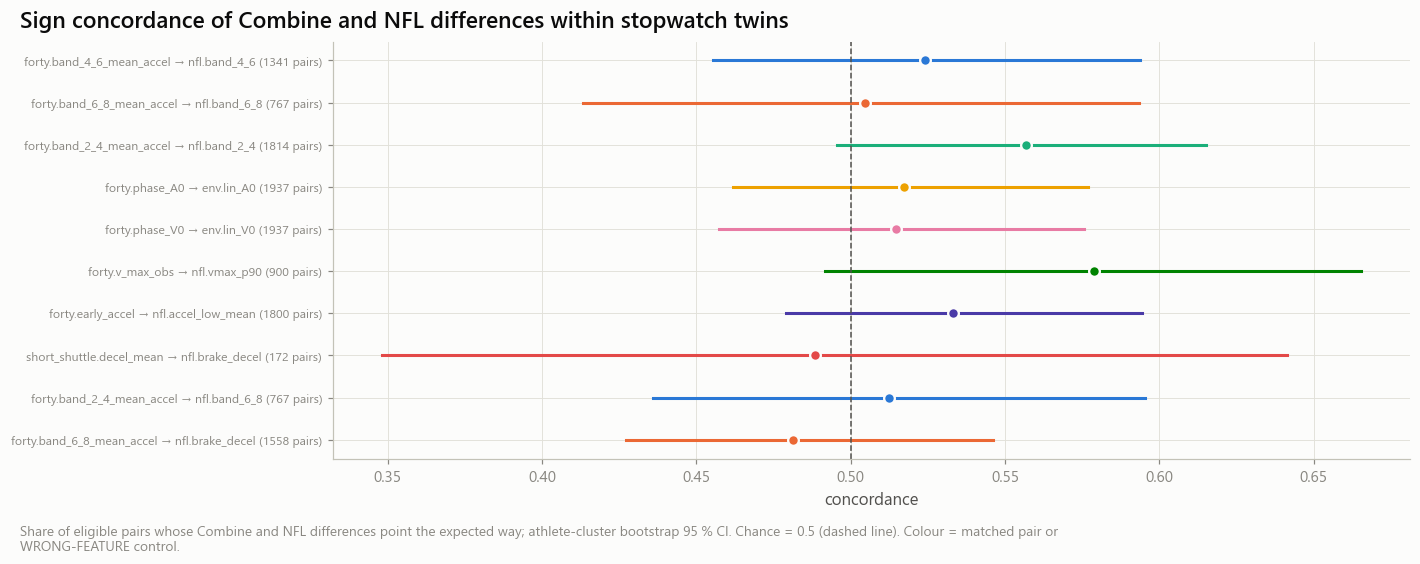

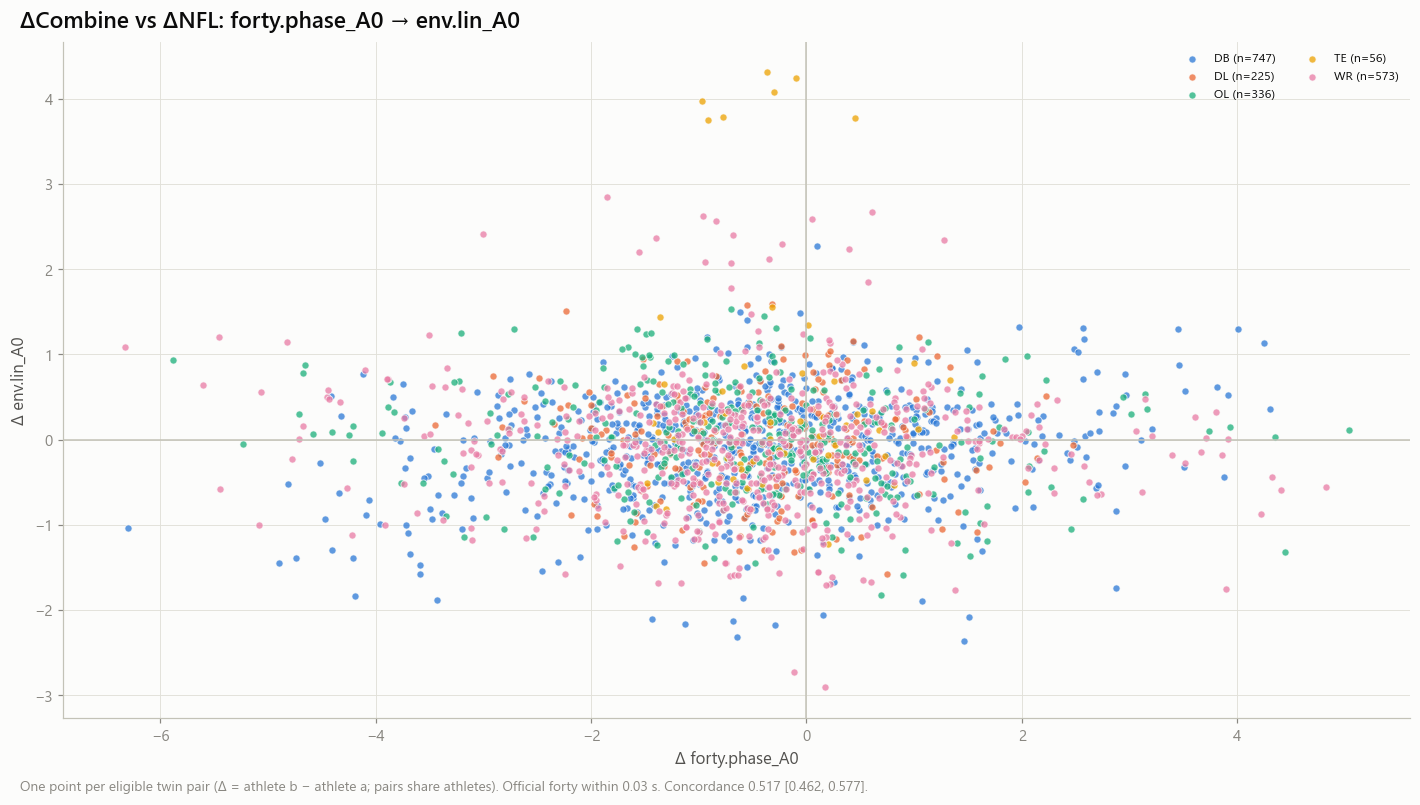

In [4]:
rows = []
for p in tw.TWIN_PAIRS:
    f = PF.get((p.combine, p.nfl))
    r = tw.analyse(f, p.expected_sign, C, C.seed) if f is not None else {'status': 'not_available', 'n_pairs': 0}
    rows.append({'combine': p.combine, 'nfl': p.nfl, 'kind': p.kind, 'note': p.note, **r})
RES = pl.DataFrame(rows, infer_schema_length=None)
W(RES, 'm11_twin_concordance')
with pl.Config(tbl_rows=-1, tbl_width_chars=260, fmt_str_lengths=50):
    display(RES.select([c for c in ('combine', 'nfl', 'kind', 'n_pairs', 'n_athletes', 'concordance', 'concordance_lo', 'concordance_hi', 'concordance_comp_lo', 'concordance_comp_hi',
                                    'disjoint_pairs', 'disjoint_concordance', 'disjoint_lo', 'disjoint_hi', 'delta_spearman', 'conditional_slope', 'conditional_slope_lo',
                                    'conditional_slope_hi', 'concordance_reliability_weighted', 'reading') if c in RES.columns]))
ok = RES.filter(pl.col('status') == 'computed').with_columns((pl.col('combine') + ' → ' + pl.col('nfl') + ' (' + pl.col('n_pairs').cast(pl.String) + ' pairs)').alias('label')) if 'status' in RES.columns else RES.clear()
if ok.height:
    store.show(fg.fig_forest(ok, 'label', 'concordance', 'concordance_lo', 'concordance_hi', 'Sign concordance of Combine and NFL differences within stopwatch twins',
                             'Share of eligible pairs whose Combine and NFL differences point the expected way; athlete-cluster bootstrap 95 % CI. Chance = 0.5 (dashed line). Colour = matched pair or WRONG-FEATURE control.',
                             'concordance', ref=0.5, color_by='kind'), 'AM11_E_02_concordance_forest', {'concordance': ok}, publication=True, source='m11_twin_concordance')
    primary = ok.filter(pl.col('kind') == 'matched').sort('n_pairs', descending=True).row(0, named=True)
    pf = PF[(primary['combine'], primary['nfl'])].join(positions.rename({'nfl_id': 'nfl_id_a'}), on='nfl_id_a', how='left')
    store.show(fg.fig_scatter(pf, 'd_combine', 'd_nfl', f"ΔCombine vs ΔNFL: {primary['combine']} → {primary['nfl']}",
                              f"One point per eligible twin pair (Δ = athlete b − athlete a; pairs share athletes). Official forty within 0.03 s. Concordance {rp.ci(primary['concordance'], primary['concordance_lo'], primary['concordance_hi'])}.",
                              f"Δ {primary['combine']}", f"Δ {primary['nfl']}", ref_line='zero'), 'AM11_E_03_delta_scatter', {'pairs': pf.drop('se_a', 'se_b', strict=False)}, publication=True, source='m11_twin_concordance')

## 3 · Controls

Random same-position pairs (as many per position as the twin analysis used) and NFL values reshuffled among athletes of the same position while the pair structure is kept. The observed concordance is drawn against both null distributions.

combine,nfl,observed,random_pairs_q95,reshuffle_q95,p_random,p_reshuffle
str,str,f64,f64,f64,f64,f64
"""forty.band_4_6_mean_accel""","""nfl.band_4_6""",0.524236,0.585308,0.54821,0.99005,0.228856
"""forty.band_6_8_mean_accel""","""nfl.band_6_8""",0.504563,0.625712,0.56721,1.0,0.482587
"""forty.band_2_4_mean_accel""","""nfl.band_2_4""",0.556781,0.584287,0.535281,0.80597,0.014925
"""forty.phase_A0""","""env.lin_A0""",0.517295,0.537718,0.534047,0.60199,0.223881
"""forty.phase_V0""","""env.lin_V0""",0.514713,0.564996,0.541381,0.995025,0.283582
"""forty.v_max_obs""","""nfl.vmax_p90""",0.578889,0.676895,0.558889,1.0,0.0199
"""forty.early_accel""","""nfl.accel_low_mean""",0.533333,0.570981,0.538444,0.930348,0.094527
"""short_shuttle.decel_mean""","""nfl.brake_decel""",0.488372,0.552828,0.5875,0.577114,0.606965


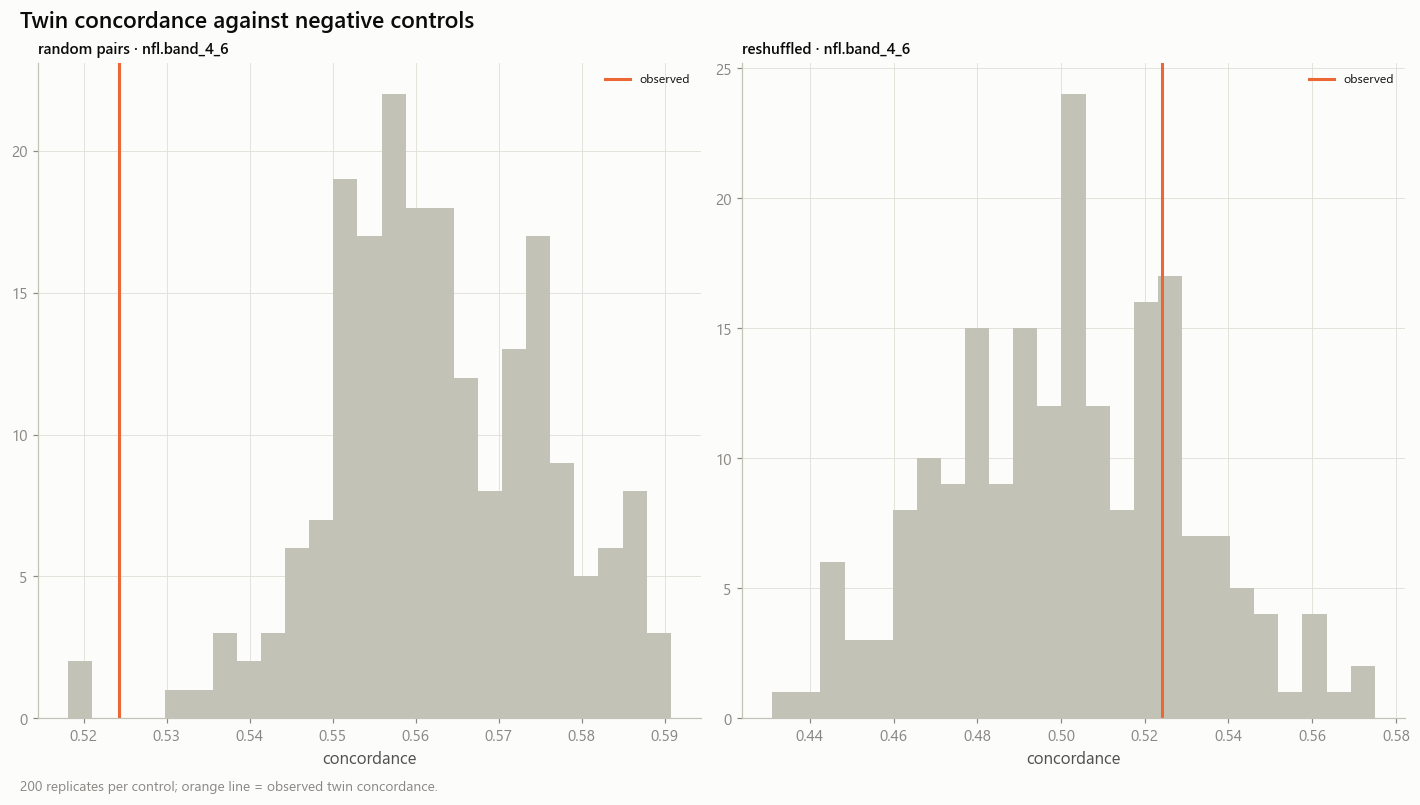

In [5]:
ctrl_rows, nulls, obs = [], {}, {}
for p in [p for p in tw.TWIN_PAIRS if p.kind == 'matched']:
    f = PF.get((p.combine, p.nfl))
    if f is None or f.height < 10:
        continue
    per_pos = dict(f.group_by('position_group').len().iter_rows())
    rnd = tw.random_pair_control(values, positions, p.combine, p.nfl, per_pos, p.expected_sign, N_CONTROL, C.seed)
    shf = tw.reshuffle_control(f, values, positions, p.nfl, p.expected_sign, N_CONTROL, C.seed)
    o = RES.filter((pl.col('combine') == p.combine) & (pl.col('nfl') == p.nfl))['concordance'][0]
    ctrl_rows.append({'combine': p.combine, 'nfl': p.nfl, 'observed': o, 'random_pairs_q95': float(np.quantile(rnd, 0.95)) if rnd.size else None,
                      'reshuffle_q95': float(np.quantile(shf, 0.95)) if shf.size else None, 'p_random': float((1 + (rnd >= o).sum()) / (1 + rnd.size)) if rnd.size else None,
                      'p_reshuffle': float((1 + (shf >= o).sum()) / (1 + shf.size)) if shf.size else None})
    if len(nulls) < 2:
        nulls[f'random pairs · {p.nfl}'], obs[f'random pairs · {p.nfl}'] = rnd, o
        nulls[f'reshuffled · {p.nfl}'], obs[f'reshuffled · {p.nfl}'] = shf, o
CTRL = pl.DataFrame(ctrl_rows) if ctrl_rows else pl.DataFrame()
W(CTRL, 'm11_twin_controls')
display(CTRL)
if nulls:
    store.show(fg.fig_null_vs_observed(nulls, obs, 'Twin concordance against negative controls', f'{N_CONTROL} replicates per control; orange line = observed twin concordance.', 'concordance'),
               'AM11_E_04_negative_controls', {}, publication=True, source='m11_twin_controls')

## 4 · Matched prospect examples (rule-chosen) and conclusion

For the primary matched pair: the three eligible twin pairs with the largest |ΔCombine| (ties by pair id). Shown as recorded; no pair is hand-picked.

pair_id,position_group,name_a,name_b,d_forty,c_a,c_b,n_a,n_b,d_combine,d_nfl
str,str,str,str,f64,f64,f64,f64,f64,f64,f64
"""57144-58333""","""WR""","""Brian Thomas""","""Jaylin Lane""",0.01,11.917397,5.585346,5.944653,7.035767,-6.332051,1.091114
"""57199-57877""","""DB""","""Calen Bullock""","""Dwight McGlothern""",-0.01,10.234045,3.934128,5.28532,4.241946,-6.299917,-1.043375
"""57337-57353""","""OL""","""Beaux Limmer""","""Nathan Thomas""",-0.03,8.384812,2.501111,2.627897,3.566844,-5.883701,0.938947


## 11E — conclusion (inconclusive; run mode full; generated 2026-10-14T23:21:59Z)

### Research question
Within stopwatch twins, do Combine tracking differences point the same way as NFL movement differences?

### Hypothesis
Sign concordance of ΔCombine and ΔNFL > 0.5 on reliable features.

### Sample
3,266 09C pairs in the pool; eligible pairs per feature × target in the eligibility table (max 1937).

### Main evidence
- forty.band_4_6_mean_accel → nfl.band_4_6 [matched]: concordance 0.524 [0.455, 0.594], disjoint 0.413 [0.325, 0.507], 1341 pairs — inconclusive
- forty.band_6_8_mean_accel → nfl.band_6_8 [matched]: concordance 0.505 [0.413, 0.594], disjoint 0.472 [0.344, 0.603], 767 pairs — inconclusive
- forty.band_2_4_mean_accel → nfl.band_2_4 [matched]: concordance 0.557 [0.495, 0.615], disjoint 0.448 [0.368, 0.529], 1814 pairs — inconclusive
- forty.phase_A0 → env.lin_A0 [matched]: concordance 0.517 [0.462, 0.577], disjoint 0.440 [0.363, 0.520], 1937 pairs — inconclusive
- forty.phase_V0 → env.lin_V0 [matched]: concordance 0.515 [0.457, 0.576], disjoint 0.460 [0.382, 0.540], 1937 pairs — inconclusive
- forty.v_max_obs → nfl.vmax_p90 [matched]: concordance 0.579 [0.492, 0.665], disjoint 0.544 [0.427, 0.657], 900 pairs — inconclusive
- forty.early_accel → nfl.accel_low_mean [matched]: concordance 0.533 [0.479, 0.594], disjoint 0.444 [0.366, 0.526], 1800 pairs — inconclusive
- short_shuttle.decel_mean → nfl.brake_decel [matched]: concordance 0.488 [0.348, 0.642], disjoint 0.405 [0.270, 0.555], 172 pairs — inconclusive
- forty.band_2_4_mean_accel → nfl.band_6_8 [control]: concordance 0.512 [0.436, 0.595], disjoint 0.396 [0.276, 0.531], 767 pairs — inconclusive
- forty.band_6_8_mean_accel → nfl.brake_decel [control]: concordance 0.481 [0.427, 0.546], disjoint 0.485 [0.401, 0.569], 1558 pairs — inconclusive
- controls nfl.band_4_6: p(random pairs) 0.990, p(reshuffle) 0.229
- controls nfl.band_6_8: p(random pairs) 1.000, p(reshuffle) 0.483
- controls nfl.band_2_4: p(random pairs) 0.806, p(reshuffle) 0.015
- controls env.lin_A0: p(random pairs) 0.602, p(reshuffle) 0.224
- controls env.lin_V0: p(random pairs) 0.995, p(reshuffle) 0.284
- controls nfl.vmax_p90: p(random pairs) 1.000, p(reshuffle) 0.020
- controls nfl.accel_low_mean: p(random pairs) 0.930, p(reshuffle) 0.095
- controls nfl.brake_decel: p(random pairs) 0.577, p(reshuffle) 0.607

### Alternative explanations
- Twins still differ in size and role; Δweight is not in the concordance statistic (it is in the conditional slope only through Δforty / Δten).
- Selection into the NFL tracking cohort can differ within a pair (exposure).

### Practical scouting relevance
Among prospects the stopwatch cannot separate, a concordant tracking difference would be the most direct scouting use of tracking — or its absence a caution.

### Limitations
- Few eligible pairs per non-forty feature.
- Pairs share athletes: the disjoint matching has far fewer pairs but independent ones.
- Association between differences, not causation.

### Next experiment
- Re-run on the next draft class with the frozen features.
- Add reliability-weighted concordance as the primary if attempt SEs are available for most athletes.


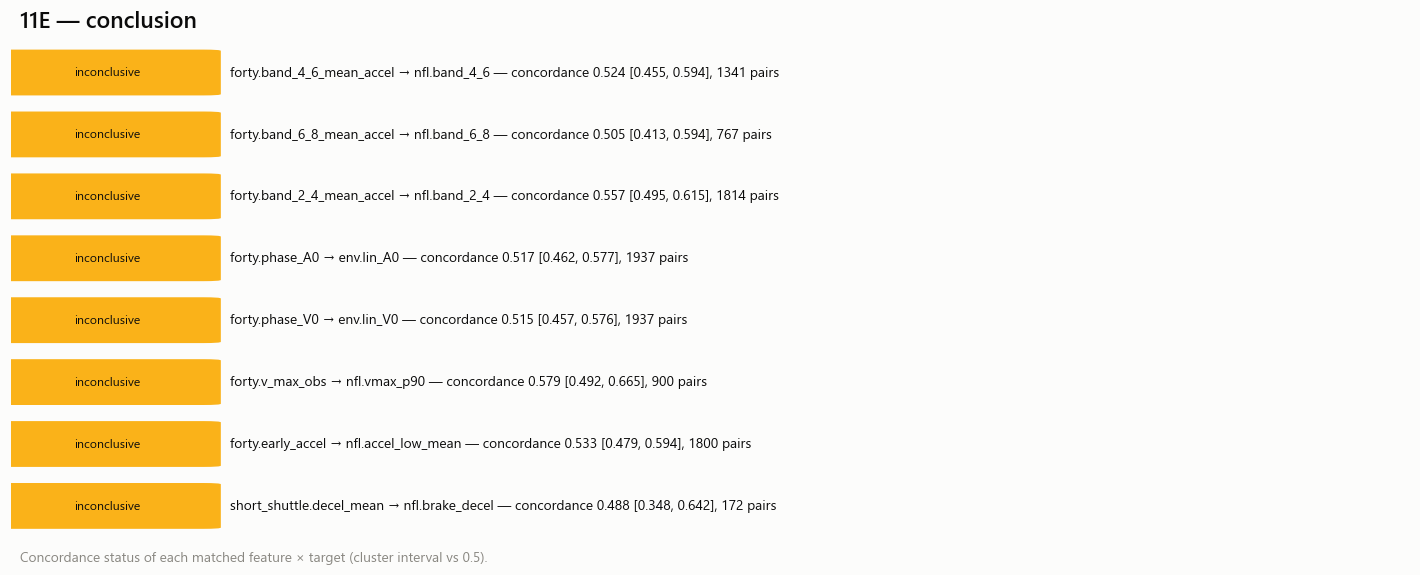

Send back: eligibility, concordance and control tables, figures AM11_E_02 / 04, the conclusion.
Next: 11d_nfl_athletic_development.ipynb


In [6]:
if ok.height:
    f = PF[(primary['combine'], primary['nfl'])]
    ex = f.with_columns(pl.col('d_combine').abs().alias('_a')).sort('_a', 'pair_id', descending=[True, False]).head(3)
    ex = ex.join(twins.select('pair_id', 'name_a', 'name_b'), on='pair_id', how='left').select('pair_id', 'position_group', 'name_a', 'name_b', 'd_forty', 'c_a', 'c_b', 'n_a', 'n_b', 'd_combine', 'd_nfl')
    W(ex, 'm11_twin_examples')
    display(ex)
evid = []
for r in (ok.iter_rows(named=True) if ok.height else []):
    if r['kind'] != 'matched':
        continue
    evid.append(tn.evidence_row(r['combine'], '11E', n_athletes=r['n_athletes'], nfl_comparison=r['nfl'], execution_mode=controls.run_mode, config_hash=C.hash(),
                                note=f"twin concordance {rp.ci(r['concordance'], r['concordance_lo'], r['concordance_hi'])}"))
W(tn.evidence_frame(evid), 'm11_metric_evidence_11E')
verd = [r['reading'] for r in (ok.filter(pl.col('kind') == 'matched').iter_rows(named=True) if ok.height else [])]
status = rp.comparison_status(verd, computed=bool(ok.height))
facts = {'status': status, 'run_mode': controls.run_mode,
         'sample': f"{twins.height:,} 09C pairs in the pool; eligible pairs per feature × target in the eligibility table (max {int(ELIG['n_pairs'].max() or 0)}).",
         'evidence': [f"{r['combine']} → {r['nfl']} [{r['kind']}]: concordance {rp.ci(r.get('concordance'), r.get('concordance_lo'), r.get('concordance_hi'))}, disjoint {rp.ci(r.get('disjoint_concordance'), r.get('disjoint_lo'), r.get('disjoint_hi'))}, {r.get('n_pairs')} pairs — {r.get('reading')}" for r in (ok.iter_rows(named=True) if ok.height else [])]
                     + [f"controls {r['nfl']}: p(random pairs) {rp.fmt(r['p_random'])}, p(reshuffle) {rp.fmt(r['p_reshuffle'])}" for r in (CTRL.iter_rows(named=True) if CTRL.height else [])],
         'alternatives': ['Twins still differ in size and role; Δweight is not in the concordance statistic (it is in the conditional slope only through Δforty / Δten).', 'Selection into the NFL tracking cohort can differ within a pair (exposure).'],
         'relevance': 'Among prospects the stopwatch cannot separate, a concordant tracking difference would be the most direct scouting use of tracking — or its absence a caution.',
         'limitations': ['Few eligible pairs per non-forty feature.', 'Pairs share athletes: the disjoint matching has far fewer pairs but independent ones.', 'Association between differences, not causation.'],
         'next': ['Re-run on the next draft class with the frozen features.', 'Add reliability-weighted concordance as the primary if attempt SEs are available for most athletes.']}
md_ = rp.conclusion_markdown('11E', facts)
display(Markdown(md_))
rp.write_conclusion(store, '11E', md_)
rp.run_manifest(store, '11E', PROV, ['m11_twin_eligibility', 'm11_twin_concordance', 'm11_twin_controls', 'm11_metric_evidence_11E'], status)
crow = pl.DataFrame([{'item': f"{r['combine']} → {r['nfl']}", 'evidence': f"concordance {rp.ci(r['concordance'], r['concordance_lo'], r['concordance_hi'])}, {r['n_pairs']} pairs",
                      'status': rp.comparison_status([r['reading']])} for r in (ok.filter(pl.col('kind') == 'matched').iter_rows(named=True) if ok.height else [])])
store.show(fg.fig_conclusion(crow, '11E — conclusion', 'Concordance status of each matched feature × target (cluster interval vs 0.5).'), 'AM11_E_05_conclusion', {}, publication=True, source='m11_twin_concordance')
print('Send back: eligibility, concordance and control tables, figures AM11_E_02 / 04, the conclusion.')
print('Next: 11d_nfl_athletic_development.ipynb')